# 网络流行语生命周期聚类分析

In [80]:
#设置中文字体和负号显示，防止显示出错
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

#导入后续操作需要用到的的库和函数（为了后续的降维操作，参考AI建议导入PCA）
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns #数据可视化
from sklearn.preprocessing import StandardScaler #数据标准化
from sklearn.cluster import KMeans #K-means聚类算法
from sklearn.decomposition import PCA #主成分分析（PCA）降维
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster #层次聚类算法和相关函数

In [81]:
#读取文件并查看数据
data = pd.read_csv('features2.csv', encoding='utf-8')
print(data.shape)
display(data.head())
print(data.columns.tolist())

(73, 10)


,keyword,peak,mean,lifecycle_days,rise_speed,skewness,kurtosis,rise_half_life,fall_half_life,trend_ratio
0,厉害了我的哥,16403,1679.98,407,339.24,3.4654,13.6693,186,1034,0.1799
1,友谊的小船,11618,505.57,566,38.67,7.6652,80.9189,516,1181,0.4369
2,吃瓜群众,16347,1043.64,751,17.12,4.6355,37.7747,1172,1080,1.0852
3,洪荒之力,564425,3712.32,677,563.32,16.4148,324.6449,1002,1028,0.9747
4,老司机,25863,5468.80,829,29.20,1.1640,1.4580,1176,1310,0.8977


['keyword', 'peak', 'mean', 'lifecycle_days', 'rise_speed', 'skewness', 'kurtosis', 'rise_half_life', 'fall_half_life', 'trend_ratio']


In [82]:
#数据准备
keyword_col = 'keyword' #定义样本名称列（关键词列）
feature_cols = ['peak','lifecycle_days','rise_speed','skewness','kurtosis', 'rise_half_life','fall_half_life','trend_ratio'] #定义用于聚类的特征列列表（9个热度/生命周期指标）

X = data[feature_cols] #从数据中提取所有特征列，生成特征矩阵X

from sklearn.preprocessing import StandardScaler #导入数据标准化工具
scaler = StandardScaler() #创建标准化模型对象
X_scaled = scaler.fit_transform(X) #对特征矩阵X进行标准化处理，得到标准化后的数据X_scaled
print(X_scaled.shape)

(73, 8)


## 方法1：系统聚类

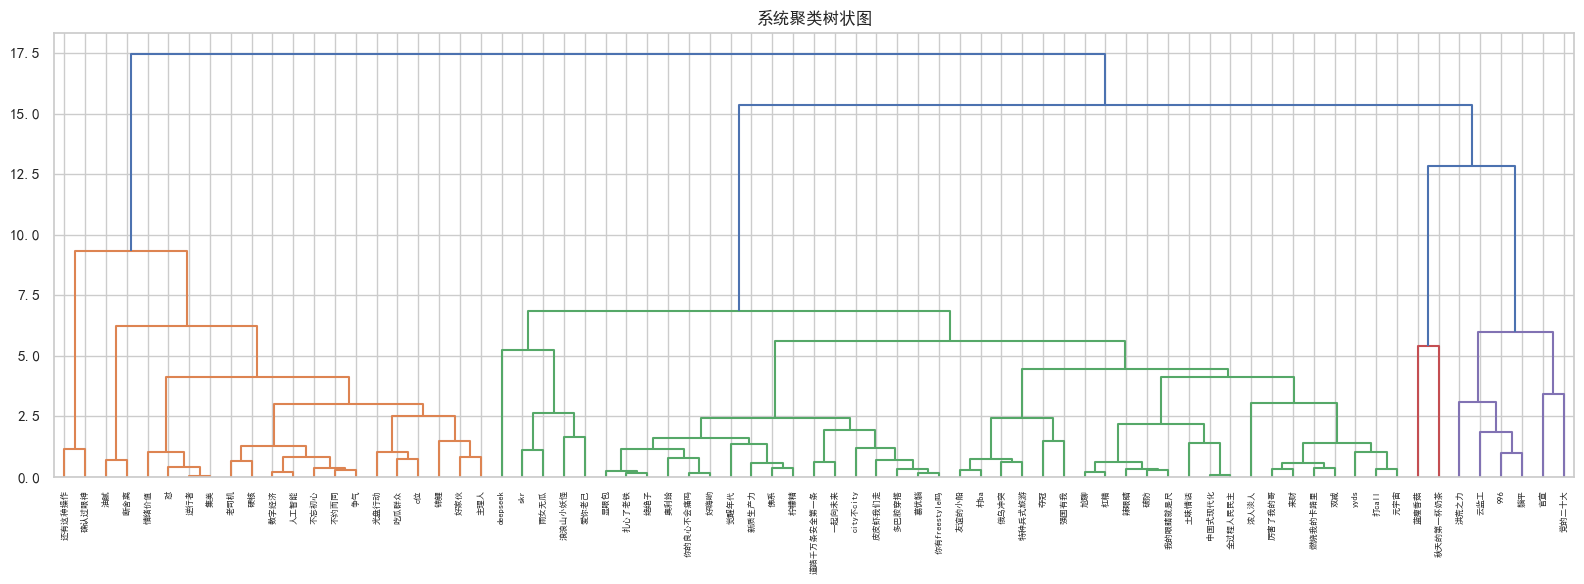

In [83]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(16,6))
dendrogram(Z,labels=data['keyword'].values,leaf_rotation=90)
plt.title('系统聚类树状图')
plt.tight_layout() #调整布局以防止标签重叠
plt.show()

In [84]:
#根据树状图调整
hier_k = 3 #根据树状图调整层次聚类的簇数为3
data['hier_cluster'] = fcluster(Z,hier_k,criterion='maxclust') #根据层次聚类结果将每个样本分配到对应的簇中，并将簇标签存储在数据框data的新列'hier_cluster'中
data[['keyword','hier_cluster']].head() #显示每个样本的关键词和对应的层次聚类簇标签，方便查看聚类结果

,keyword,hier_cluster
0,厉害了我的哥,2
1,友谊的小船,2
2,吃瓜群众,1
3,洪荒之力,3
4,老司机,1


## 方法2：K-Means聚类 + 肘部法则

d:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

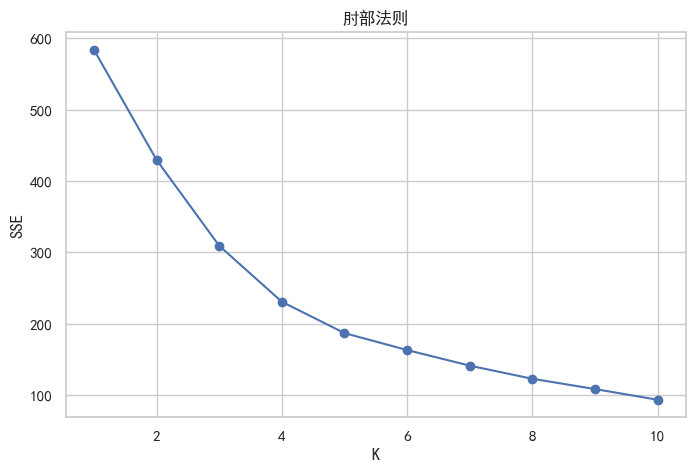

In [85]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']  # 设置中文字体为黑体
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示为方块

sse = [] # 存储不同K值对应的SSE

for k in range(1,11):
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    km.fit(X_scaled)
    sse.append(km.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,11), sse, marker='o')
plt.xlabel('K')
plt.ylabel('SSE')
plt.title('肘部法则')
plt.show()

In [86]:
# 根据肘部法则修改
best_k = 3

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

data['kmeans_cluster'] = kmeans.fit_predict(X_scaled) + 1

data[['keyword','kmeans_cluster']].head()

d:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,keyword,kmeans_cluster
0,厉害了我的哥,1
1,友谊的小船,1
2,吃瓜群众,2
3,洪荒之力,3
4,老司机,2


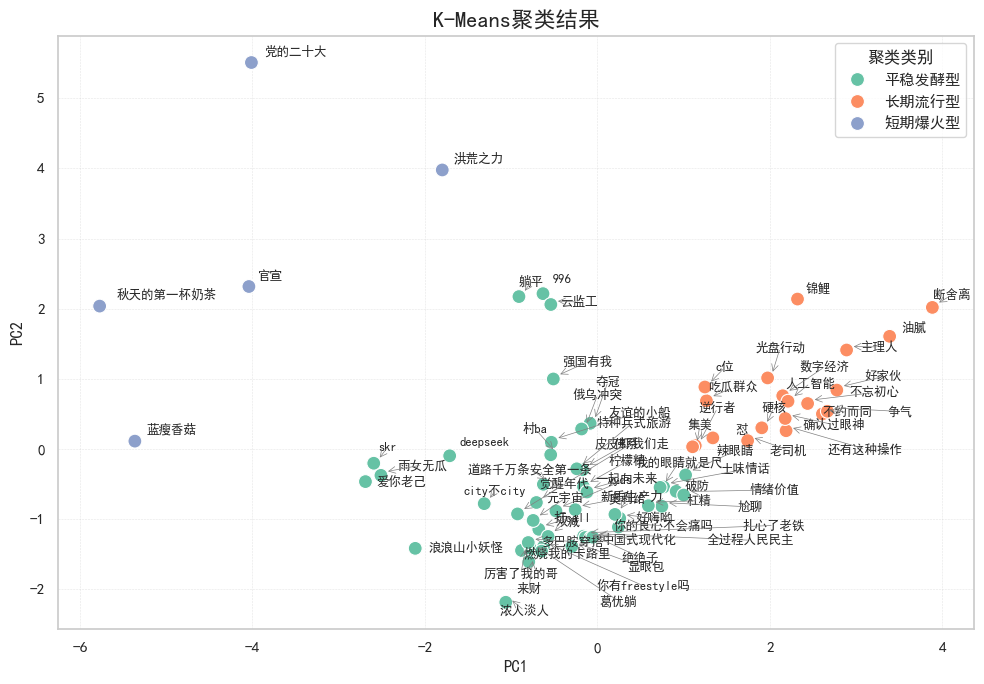

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from adjustText import adjust_text


cluster_map = {
    1: '平稳发酵型',
    2: '长期流行型',
    3: '短期爆火型'
}
data['cluster_label'] = data['kmeans_cluster'].astype(int).map(cluster_map)
cluster_order = ['平稳发酵型', '长期流行型', '短期爆火型']

# PCA可视化
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(10,7))
sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=data['cluster_label'],
    hue_order=cluster_order,
    palette='Set2',
    s=100)
plt.title('K-Means聚类结果', fontsize=16)
plt.xlabel('PC1', fontsize=12)
plt.ylabel('PC2', fontsize=12)

# 添加热词标签，避免重叠
texts = []
for i, txt in enumerate(data['keyword']): 
    # 首先把文本放在点附近
    texts.append(plt.text(X_pca[i,0]+0.05, X_pca[i,1]+0.05, txt, fontsize=9))
    
# 由AI得到调整文字避免重叠并用引导线连接的代码建议
adjust_text(
    texts, 
    X=X_pca[:,0],
    Y=X_pca[:,1],
    arrowprops=dict(arrowstyle='->', color='gray', lw=0.5),
    expand_points=(1.2,1.2),
    force_points=0.2)

plt.legend(title='聚类类别')
plt.grid(True, linestyle='--', linewidth=0.4, alpha=0.5)
plt.tight_layout()
plt.show()

## 聚类类别解释

In [88]:
# 热度等级

peak_q33 = data['peak'].quantile(0.33)
peak_q66 = data['peak'].quantile(0.66)

def hotness_level(x):
    if x >= peak_q66:
        return '高热度'
    elif x >= peak_q33:
        return '中热度'
    else:
        return '低热度'

data['热度等级'] = data['peak'].apply(hotness_level)

In [89]:
# 传播态势

life_q25 = data['lifecycle_days'].quantile(0.25)
life_q50 = data['lifecycle_days'].quantile(0.50)
life_q75 = data['lifecycle_days'].quantile(0.75)

def trend_type(x):

    if x >= life_q75:
        return '长期流行'

    elif x >= life_q50:
        return '中长期流行'

    elif x >= life_q25:
        return '平稳发酵'

    else:
        return '短期爆火'

data['传播态势'] = data['lifecycle_days'].apply(trend_type)

data[['keyword','热度等级','传播态势']].head()

,keyword,热度等级,传播态势
0,厉害了我的哥,中热度,短期爆火
1,友谊的小船,中热度,平稳发酵
2,吃瓜群众,中热度,中长期流行
3,洪荒之力,高热度,中长期流行
4,老司机,中热度,长期流行


In [90]:
# 类别描述生成

cluster_report = []

for cluster_id, group in data.groupby('kmeans_cluster'):

    hotness = group['热度等级'].mode()[0]
    trend = group['传播态势'].mode()[0]

    peak_mean = group['peak'].mean()
    life_mean = group['lifecycle_days'].mean()
    kurt_mean = group['kurtosis'].mean()

    if trend == '短期爆火':
        label = '短期爆火型'

    elif trend == '平稳发酵':
        label = '平稳发酵型'

    elif trend == '中长期流行':
        label = '中长期流行型'

    else:
        label = '长期流行型'

    cluster_report.append({
        '聚类类别': cluster_id,
        '类别命名': label,
        '热度等级': hotness,
        '传播态势': trend,
        '平均峰值': round(peak_mean,2),
        '平均生命周期': round(life_mean,2),
        '平均峰度': round(kurt_mean,2),
        '样本数量': len(group),
        '代表热词': '、'.join(group['keyword'].head(5))
    })

cluster_report = pd.DataFrame(cluster_report)

cluster_report

,聚类类别,类别命名,热度等级,传播态势,平均峰值,平均生命周期,平均峰度,样本数量,代表热词
0,1,平稳发酵型,高热度,平稳发酵,83436.35,510.83,39.50,48,厉害了我的哥、友谊的小船、葛优躺、辣眼睛、你有freestyle吗
1,2,长期流行型,低热度,长期流行,14140.15,923.10,14.08,20,吃瓜群众、老司机、怼、油腻、还有这种操作
2,3,短期爆火型,高热度,短期爆火,727720.60,430.80,309.02,5,洪荒之力、蓝瘦香菇、官宣、秋天的第一杯奶茶、党的二十大


In [91]:
# 热词最终分类结果
final_result = data[[
    'keyword',
    'kmeans_cluster',
    '热度等级',
    '传播态势'
]]

display(final_result.head())

final_result.to_csv(
    '热词聚类结果.csv',
    index=False,
    encoding='utf-8-sig'
)

cluster_report.to_csv(
    '聚类类别说明.csv',
    index=False,
    encoding='utf-8-sig'
)

print('文件已导出')

,keyword,kmeans_cluster,热度等级,传播态势
0,厉害了我的哥,1,中热度,短期爆火
1,友谊的小船,1,中热度,平稳发酵
2,吃瓜群众,2,中热度,中长期流行
3,洪荒之力,3,高热度,中长期流行
4,老司机,2,中热度,长期流行


文件已导出


## 聚类评估与对比

In [92]:
from sklearn.metrics import silhouette_score

# K-Means轮廓系数
silhouette_kmeans = silhouette_score(X_scaled, data['kmeans_cluster'])
print(f'K-Means 聚类轮廓系数: {silhouette_kmeans:.3f}')

# 系统聚类轮廓系数
silhouette_hier = silhouette_score(X_scaled, data['hier_cluster'])
print(f'系统聚类轮廓系数: {silhouette_hier:.3f}')

# 对比表格
compare_df = pd.DataFrame({
    '方法': ['K-Means','系统聚类'],
    '轮廓系数': [silhouette_kmeans, silhouette_hier]
})
compare_df

K-Means 聚类轮廓系数: 0.383
系统聚类轮廓系数: 0.380


,方法,轮廓系数
0,K-Means,0.382874
1,系统聚类,0.380192


## 聚类中心特征与自动命名

In [93]:
# 计算每类中心特征
cluster_centers = data.groupby('kmeans_cluster')[feature_cols].mean()

cluster_center_desc = []
for idx, row in cluster_centers.iterrows():
    # 自动命名逻辑
    if row['peak'] >= data['peak'].quantile(0.66) and row['lifecycle_days'] < data['lifecycle_days'].quantile(0.33):
        label = '短期爆火型'
    elif row['lifecycle_days'] >= data['lifecycle_days'].quantile(0.75):
        label = '长期流行型'
    elif row['lifecycle_days'] >= data['lifecycle_days'].quantile(0.50):
        label = '中长期流行型'
    else:
        label = '平稳发酵型'
    
    cluster_center_desc.append({
        '聚类编号': idx,
        '类别命名': label,
        **row.to_dict()
    })

cluster_center_desc_df = pd.DataFrame(cluster_center_desc)
cluster_center_desc_df

,聚类编号,类别命名,peak,lifecycle_days,rise_speed,skewness,kurtosis,rise_half_life,fall_half_life,trend_ratio
0,1,平稳发酵型,83436.354167,510.833333,647.858958,4.268887,39.497598,442.729167,1088.770833,0.434752
1,2,长期流行型,14140.150000,923.100000,30.912500,2.553170,14.075335,1352.800000,1525.300000,1.052300
2,3,短期爆火型,727720.600000,430.800000,37437.366000,15.711740,309.018640,323.400000,968.000000,0.310580
